# Retail A/B Testing & Customer Analytics
 *Python, SQL*

**Business Question**

Did the February–April 2019 trial improve sales at stores 77, 86 and 88, and what customer behavior explains their performance?

**A/B Testing Approach**

A/B testing compares a **trial group** against a **control group** to understand whether a change had a significant impact.

In this project, stores **77, 86, and 88** are the trial (treatment) stores. Each trial store will be matched with a similar control store based on performance before the February–April 2019 trial.

The analysis will look at:

* Did sales increase during the trial?
* Did the trial stores outperform similar control stores?
* Was the difference statistically significant?
* Did sales increase because of more customers?
* Did customers make more purchases?
* Which customer segments are the most valuable?

The results will help determine whether the trial was successful and whether the business should consider expanding it to other stores

#### **Step 1. Import the libraries**





First, I import the Python libraries needed for data analysis, SQL, visualization and statistical test



In [2]:
# import libraries
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
from scipy import stats

#### **Step 2. Load the data**


Next, I will load the data into pandas DataFrame.

There are 3 datasets:

*  QVI Transaction data
*  QVI Customer purchase behavior data
*  Combined QVI data

I will preview first 5 rows of each dataset

In [3]:
# Load the three files from the folder where this notebook is running.
transactions = pd.read_excel('QVI_transaction_data.xlsx')
customers = pd.read_csv('QVI_purchase_behaviour.csv')
df = pd.read_csv('QVI_data.csv')

#### **Step 3. Preview the data**
Next, I will preview the first 5 rows of each dataset to understand structure and fields

In [4]:
# Preview the first 5 rows of data
display(transactions.head())
display(customers.head())
display(df.head())

,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES
0,43390,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.0
1,43599,1,1307,348,66,CCs Nacho Cheese 175g,3,6.3
2,43605,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.9
3,43329,2,2373,974,69,Smiths Chip Thinly S/Cream&Onion 175g,5,15.0
4,43330,2,2426,1038,108,Kettle Tortilla ChpsHny&Jlpno Chili 150g,3,13.8


,LYLTY_CARD_NBR,LIFESTAGE,PREMIUM_CUSTOMER
0,1000,YOUNG SINGLES/COUPLES,Premium
1,1002,YOUNG SINGLES/COUPLES,Mainstream
2,1003,YOUNG FAMILIES,Budget
3,1004,OLDER SINGLES/COUPLES,Mainstream
4,1005,MIDAGE SINGLES/COUPLES,Mainstream


,LYLTY_CARD_NBR,DATE,STORE_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES,PACK_SIZE,BRAND,LIFESTAGE,PREMIUM_CUSTOMER
0,1000,2018-10-17,1,1,5,Natural Chip Compny SeaSalt175g,2,6.0,175,NATURAL,YOUNG SINGLES/COUPLES,Premium
1,1002,2018-09-16,1,2,58,Red Rock Deli Chikn&Garlic Aioli 150g,1,2.7,150,RRD,YOUNG SINGLES/COUPLES,Mainstream
2,1003,2019-03-07,1,3,52,Grain Waves Sour Cream&Chives 210G,1,3.6,210,GRNWVES,YOUNG FAMILIES,Budget
3,1003,2019-03-08,1,4,106,Natural ChipCo Hony Soy Chckn175g,1,3.0,175,NATURAL,YOUNG FAMILIES,Budget
4,1004,2018-11-02,1,5,96,WW Original Stacked Chips 160g,1,1.9,160,WOOLWORTHS,OLDER SINGLES/COUPLES,Mainstream


#### **Step 4. Data Quality Check**
Before I analyze the the data, I need to inspect the data for the following:

* Number of observations
* Duplicate records
* Missing values
* Data distribution
* Possible outliers



In [5]:
# Count records, customers and stores, and check the available columns.
# Number of observations in terms of number of rows and columns
print("Rows: ", df.shape[0])
print("Columns: ", df.shape[1])

# of loyalty customers
total_customers = df["LYLTY_CARD_NBR"].nunique()
print(f"Total Loyalty Customers: {total_customers:,}")

# total # of stores
total_stores = df["STORE_NBR"].nunique()
print(f"Total Stores: {total_stores:,}")

# column names and data types
print(df.columns)
print("\nData Types:")
df.dtypes

Rows:  264834
Columns:  12
Total Loyalty Customers: 72,636
Total Stores: 272
Index(['LYLTY_CARD_NBR', 'DATE', 'STORE_NBR', 'TXN_ID', 'PROD_NBR',
       'PROD_NAME', 'PROD_QTY', 'TOT_SALES', 'PACK_SIZE', 'BRAND', 'LIFESTAGE',
       'PREMIUM_CUSTOMER'],
      dtype='object')

Data Types:


,0
LYLTY_CARD_NBR,int64
DATE,object
STORE_NBR,int64
TXN_ID,int64
PROD_NBR,int64
PROD_NAME,object
PROD_QTY,int64
TOT_SALES,float64
PACK_SIZE,int64
BRAND,object


In [6]:
# Check for duplicate records
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  1


In [7]:
# Show the repeated row so it can be checked.
#return the duplicated record
df[df.duplicated()]

,LYLTY_CARD_NBR,DATE,STORE_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES,PACK_SIZE,BRAND,LIFESTAGE,PREMIUM_CUSTOMER
106249,107024,2018-10-01,107,108462,45,Smiths Thinly Cut Roast Chicken 175g,2,6.0,175,SMITHS,OLDER SINGLES/COUPLES,Premium


In [8]:
# Check for missing values (null values)
df.isnull().sum()

,0
LYLTY_CARD_NBR,0
DATE,0
STORE_NBR,0
TXN_ID,0
PROD_NBR,0
PROD_NAME,0
PROD_QTY,0
TOT_SALES,0
PACK_SIZE,0
BRAND,0


In [9]:
#Check the data distribution
df[["PROD_QTY", "TOT_SALES"]].describe()

,PROD_QTY,TOT_SALES
count,264834.000000,264834.000000
mean,1.905813,7.299346
std,0.343436,2.527241
min,1.000000,1.500000
25%,2.000000,5.400000
50%,2.000000,7.400000
75%,2.000000,9.200000
max,5.000000,29.500000


To check unusually large or small purchases, we look at the middle half of the values. This spread is called the **interquartile range (IQR)**.

Values far beyond that spread are outliers and will be flagged for review. A flag does not mean the purchase is wrong, so flagged purchases are not automatically removed.

In [10]:
# Identify outliers in TOT_SALES using the IQR method

Q1 = df["TOT_SALES"].quantile(0.25)
Q3 = df["TOT_SALES"].quantile(0.75)
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers_sales = df[
    (df["TOT_SALES"] < lower_bound) |
    (df["TOT_SALES"] > upper_bound)
]

# Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Minimum Sales:", df["TOT_SALES"].min())
print("Maximum Sales:", df["TOT_SALES"].max())
print("Number of Outliers:", len(outliers_sales))

Q1: 5.4
Q3: 9.2
IQR: 3.799999999999999
Lower Bound: -0.29999999999999805
Upper Bound: 14.899999999999999
Minimum Sales: 1.5
Maximum Sales: 29.5
Number of Outliers: 576


In [11]:
# Identify outliers in PROD_QTY using the IQR method

Q1 = df["PROD_QTY"].quantile(0.25)
Q3 = df["PROD_QTY"].quantile(0.75)
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[
    (df["PROD_QTY"] < lower_bound) |
    (df["PROD_QTY"] > upper_bound)
]

# Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Minimum:", df["PROD_QTY"].min())
print("Maximum:", df["PROD_QTY"].max())
print("Number of Outliers:", len(outliers))

Q1: 2.0
Q3: 2.0
IQR: 0.0
Lower Bound: 2.0
Upper Bound: 2.0
Minimum: 1
Maximum: 5
Number of Outliers: 28795


#### **Step 5. Data Cleaning**

After I have identified the issues, I will clean the data for analysis

* Removing duplicate records
* Standardize date format
* Handle outliers that can skew the data

Then, I will validate data is ready for analysis


In [12]:
# Remove exact copies of the same row.
df = df.drop_duplicates().copy()
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [13]:
# standardize date format
# this step is needed to create new column called Year Month
df["DATE"] = pd.to_datetime(df["DATE"])

In [14]:
# Check the cleaned table and its date range.
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nDuplicates:")
print(df.duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)


Rows: 264833
Columns: 12

Duplicates:
0

Missing Values:
LYLTY_CARD_NBR      0
DATE                0
STORE_NBR           0
TXN_ID              0
PROD_NBR            0
PROD_NAME           0
PROD_QTY            0
TOT_SALES           0
PACK_SIZE           0
BRAND               0
LIFESTAGE           0
PREMIUM_CUSTOMER    0
dtype: int64

Data Types:
LYLTY_CARD_NBR               int64
DATE                datetime64[ns]
STORE_NBR                    int64
TXN_ID                       int64
PROD_NBR                     int64
PROD_NAME                   object
PROD_QTY                     int64
TOT_SALES                  float64
PACK_SIZE                    int64
BRAND                       object
LIFESTAGE                   object
PREMIUM_CUSTOMER            object
dtype: object


#### **Step 6. Feature Engineering**
Create a 'Year-Month' column to analyze monthly sales trends and track A/B testing results.

In [15]:
# Create new column called Year-Month. This column will be used for monthly sales trend analysis
df["YEAR_MONTH"] = (
    df["DATE"]
    .dt.to_period("M")
    .astype(str)
)

df[["DATE", "YEAR_MONTH"]].head()

# date range of complete data
total_months = df["YEAR_MONTH"].nunique()
print(f"Total Months of Data: {total_months}")

Total Months of Data: 12


#### **Step 7. Data Analysis**

After completing the data quality checks, cleaning, and preparation, the dataset is ready for analysis.

Data will be analyzed for the following:

- Sales performance
- Monthly sales trends
- Store performance
- Product and brand performance
- Customer purchasing behavior
- Customer distribution and performance by 'Lifestage' and 'Premium' level
- Customer segmentation based on RFM (recency, frequency, monetary)

The results establish an overall view of business performance before moving into the store trial A/B testing analysis.

In [16]:
#Set up SQLite to calculate KPIs and analyze sales performance
conn = sqlite3.connect(
    ":memory:"
)

df.to_sql(
    "sales",
    conn,
    index=False,
    if_exists="replace"
)

query = """
SELECT *
FROM sales
LIMIT 5;
"""

pd.read_sql_query(
    query,
    conn
)

,LYLTY_CARD_NBR,DATE,STORE_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES,PACK_SIZE,BRAND,LIFESTAGE,PREMIUM_CUSTOMER,YEAR_MONTH
0,1000,2018-10-17 00:00:00,1,1,5,Natural Chip Compny SeaSalt175g,2,6.0,175,NATURAL,YOUNG SINGLES/COUPLES,Premium,2018-10
1,1002,2018-09-16 00:00:00,1,2,58,Red Rock Deli Chikn&Garlic Aioli 150g,1,2.7,150,RRD,YOUNG SINGLES/COUPLES,Mainstream,2018-09
2,1003,2019-03-07 00:00:00,1,3,52,Grain Waves Sour Cream&Chives 210G,1,3.6,210,GRNWVES,YOUNG FAMILIES,Budget,2019-03
3,1003,2019-03-08 00:00:00,1,4,106,Natural ChipCo Hony Soy Chckn175g,1,3.0,175,NATURAL,YOUNG FAMILIES,Budget,2019-03
4,1004,2018-11-02 00:00:00,1,5,96,WW Original Stacked Chips 160g,1,1.9,160,WOOLWORTHS,OLDER SINGLES/COUPLES,Mainstream,2018-11


### Measures of shopping activity
The next queries calculate average sales and units per shopping visit, then average visits per month and per store. We also show product-line averages separately: one visit can include more than one product line.

In [17]:
# SQL query to run Average sales per transaction KPI
query = """
SELECT
    AVG(transaction_sales) AS avg_sales_per_transaction
FROM (
    SELECT
        TXN_ID,
        SUM(TOT_SALES) AS transaction_sales
    FROM sales
    GROUP BY TXN_ID
);
"""

pd.read_sql_query(
    query,
    conn
)

,avg_sales_per_transaction
0,7.346733


In [18]:
#SQL query to run Average quantity per transaction KPI
query = """
SELECT
    AVG(quantity) AS avg_quantity_per_transaction
FROM (
    SELECT
        TXN_ID,
        SUM(PROD_QTY) AS quantity
    FROM sales
    GROUP BY TXN_ID
);
"""

pd.read_sql_query(
    query,
    conn
)

,avg_quantity_per_transaction
0,1.918183


In [19]:
#SQL query to run Average transactions per month KPI
query = """
SELECT
    AVG(monthly_transactions) AS avg_transactions_per_month
FROM (
    SELECT
        YEAR_MONTH,
        COUNT(DISTINCT TXN_ID) AS monthly_transactions
    FROM sales
    GROUP BY YEAR_MONTH
);
"""

pd.read_sql_query(
    query,
    conn
)

,avg_transactions_per_month
0,21927.25


In [20]:
#SQL query to run Average transactions per store KPI
query = """
SELECT
    AVG(store_transactions) AS avg_transactions_per_store
FROM (
    SELECT
        STORE_NBR,
        COUNT(DISTINCT TXN_ID) AS store_transactions
    FROM sales
    GROUP BY STORE_NBR
);
"""

pd.read_sql_query(
    query,
    conn)

,avg_transactions_per_store
0,967.371324


In [21]:
#Sales analysis - Looking at monthly sales over time
query = """
SELECT
    YEAR_MONTH,
    SUM(TOT_SALES) AS total_sales
FROM sales
GROUP BY YEAR_MONTH
ORDER BY YEAR_MONTH;
"""

monthly_sales = pd.read_sql_query(
    query,
    conn
)

monthly_sales

,YEAR_MONTH,total_sales
0,2018-07,165275.30
1,2018-08,158081.05
2,2018-09,160522.00
3,2018-10,164409.70
4,2018-11,160233.70
5,2018-12,167913.40
6,2019-01,162642.30
7,2019-02,150665.00
8,2019-03,166265.20
9,2019-04,159845.10


,YEAR_MONTH,total_sales,MoM_Growth
0,2018-07,165275.30,NaN
1,2018-08,158081.05,-4.35
2,2018-09,160522.00,1.54
3,2018-10,164409.70,2.42
4,2018-11,160233.70,-2.54
5,2018-12,167913.40,4.79
6,2019-01,162642.30,-3.14
7,2019-02,150665.00,-7.36
8,2019-03,166265.20,10.35
9,2019-04,159845.10,-3.86


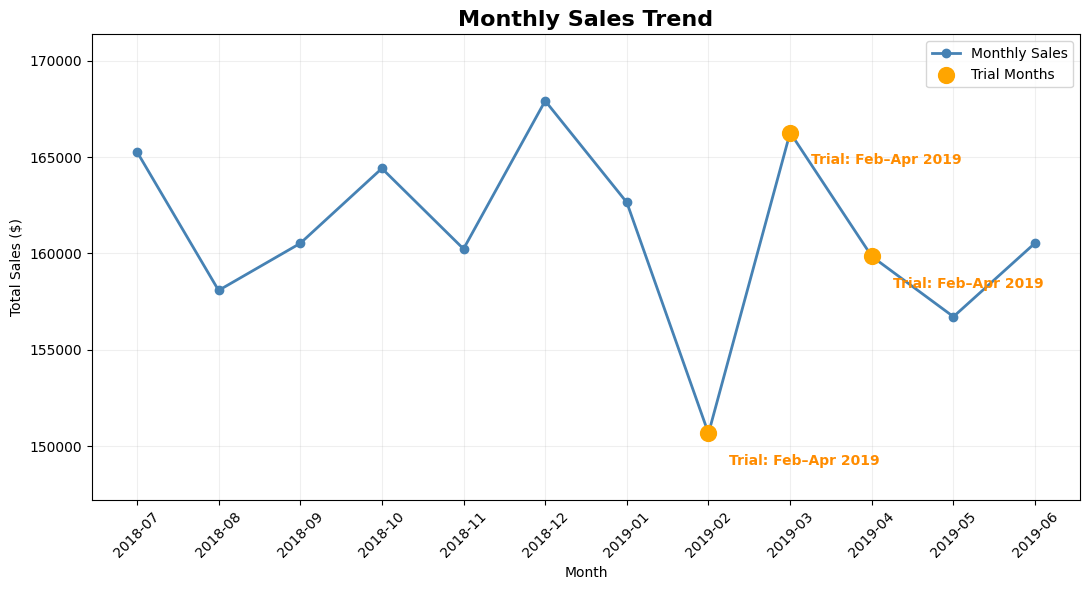

In [22]:
# Show monthly sales and mark the three trial months.
import matplotlib.pyplot as plt

# Calculate Month-over-Month (MoM) sales growth
monthly_sales["MoM_Growth"] = (
    monthly_sales["total_sales"].pct_change() * 100
)

display(monthly_sales.round(2))

# Create monthly sales trend chart
plt.figure(figsize=(11, 6))

plt.plot(
    monthly_sales["YEAR_MONTH"],
    monthly_sales["total_sales"],
    marker="o",
    linewidth=2,
    color="steelblue",
    label="Monthly Sales"
)

# Highlight February 2019 (Trial Month)
trial = monthly_sales[
    monthly_sales["YEAR_MONTH"].between("2019-02", "2019-04")
]

plt.scatter(
    trial["YEAR_MONTH"],
    trial["total_sales"],
    color="orange",
    s=130,
    zorder=5,
    label="Trial Months"
)

# Add label next to the orange point (no arrow)
for _, row in trial.iterrows():
    plt.annotate(
        "Trial: Feb–Apr 2019",
        xy=(row["YEAR_MONTH"], row["total_sales"]),
        xytext=(15, -20),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="darkorange"
    )

# Chart formatting
plt.title(
    "Monthly Sales Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.2)
plt.margins(y=0.2)
plt.tight_layout()

# Save high-resolution image for presentation
plt.savefig(
    "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
# Compare recorded sales, customers and shopping visits across stores.
# Store performance analysis
# compare stores using total sales, number of customers, and transactions
# determine low performing and high performing stores
query = """
SELECT
    STORE_NBR,
    SUM(TOT_SALES) AS total_sales,
    COUNT(DISTINCT LYLTY_CARD_NBR) AS customers,
    COUNT(DISTINCT TXN_ID) AS transactions
FROM sales
GROUP BY STORE_NBR
ORDER BY total_sales DESC;
"""

store_performance = pd.read_sql_query(
    query,
    conn
)

store_performance

,STORE_NBR,total_sales,customers,transactions
0,226,17605.45,381,2008
1,88,16333.25,388,1857
2,165,15973.75,390,1806
3,40,15559.50,388,1756
4,237,15539.50,382,1773
...,...,...,...,...
267,206,7.60,2,2
268,252,7.40,2,2
269,11,6.70,2,2
270,76,6.00,1,1


In [24]:
# Show the ten stores with the most recorded sales.
store_performance.head(10)

,STORE_NBR,total_sales,customers,transactions
0,226,17605.45,381,2008
1,88,16333.25,388,1857
2,165,15973.75,390,1806
3,40,15559.50,388,1756
4,237,15539.50,382,1773
5,58,15251.45,393,1727
6,199,14797.00,376,1671
7,4,14647.65,379,1667
8,203,14551.60,397,1650
9,26,14469.30,377,1632


In [25]:
# Show the ten stores with the least recorded sales; some have very few observed months.
store_performance.tail(10)

,STORE_NBR,total_sales,customers,transactions
262,117,161.8,43,46
263,31,14.8,2,2
264,85,13.9,3,3
265,193,13.1,3,3
266,92,9.2,1,1
267,206,7.6,2,2
268,252,7.4,2,2
269,11,6.7,2,2
270,76,6.0,1,1
271,211,5.2,2,2


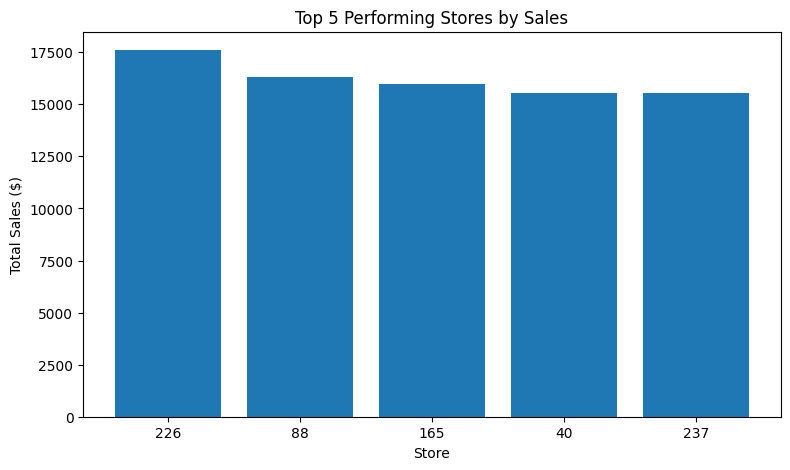

In [26]:
# Draw the five stores with the most sales.
# this code is displaying top 5 stores by sales

top_stores = store_performance.head(5)

plt.figure(figsize=(9, 5))

plt.bar(
    top_stores["STORE_NBR"].astype(str),
    top_stores["total_sales"]
)

plt.title("Top 5 Performing Stores by Sales")
plt.xlabel("Store")
plt.ylabel("Total Sales ($)")

plt.show()

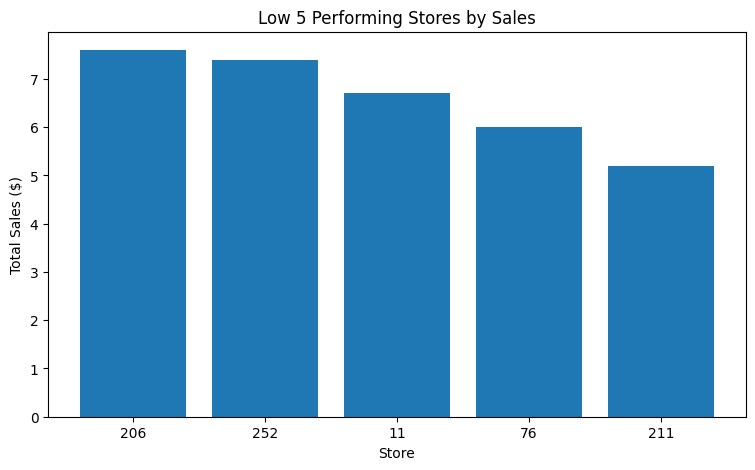

In [27]:
# Draw the five stores with the least sales.
# this code is showing lowest performing store by least sales
low_performing_stores = store_performance.tail(5)

plt.figure(figsize=(9, 5))
plt.bar(
    low_performing_stores["STORE_NBR"].astype(str),
    low_performing_stores["total_sales"],
)
plt.title("Low 5 Performing Stores by Sales")
plt.xlabel("Store")
plt.ylabel("Total Sales ($)")
plt.show()

In [28]:
# Compare products by units sold and sales.
# Product performance analysis - compare products based on units sold and total sales
query = """
SELECT
    PROD_NAME,
    SUM(PROD_QTY) AS units_sold,
    SUM(TOT_SALES) AS total_sales
FROM sales
GROUP BY PROD_NAME
ORDER BY units_sold DESC;
"""

product_performance = pd.read_sql_query(
    query,
    conn
)
# Most popular products
product_performance.head(5)

,PROD_NAME,units_sold,total_sales
0,Kettle Mozzarella Basil & Pesto 175g,6381,34457.4
1,Kettle Tortilla ChpsHny&Jlpno Chili 150g,6309,29021.4
2,Cobs Popd Sea Salt Chips 110g,6277,23852.6
3,Cobs Popd Swt/Chlli &Sr/Cream Chips 110g,6256,23772.8
4,Tostitos Splash Of Lime 175g,6234,27429.6


In [29]:
# Show the products with the fewest units sold.
# Least popular products
product_performance.tail(5)

,PROD_NAME,units_sold,total_sales
109,RRD Pc Sea Salt 165g,2702,8106.0
110,Woolworths Medium Salsa 300g,2700,4050.0
111,NCC Sour Cream & Garden Chives 175g,2682,8046.0
112,WW Crinkle Cut Original 175g,2666,4532.2
113,French Fries Potato Chips 175g,2643,7929.0


In [30]:
# Compare brands by units sold and sales.
# Brand Performance analysis - compare brands based on total units sold and total sales
query = """
SELECT
    BRAND,
    SUM(PROD_QTY) AS units_sold,
    SUM(TOT_SALES) AS total_sales
FROM sales
GROUP BY BRAND
ORDER BY total_sales DESC;
"""

brand_performance = pd.read_sql_query(
    query,
    conn
)

# Most popular brands
brand_performance.head(5)

,BRAND,units_sold,total_sales
0,KETTLE,79051,390239.8
1,DORITOS,53816,240590.9
2,SMITHS,60337,224654.2
3,PRINGLES,48019,177655.5
4,INFUZIONS,27119,99047.6


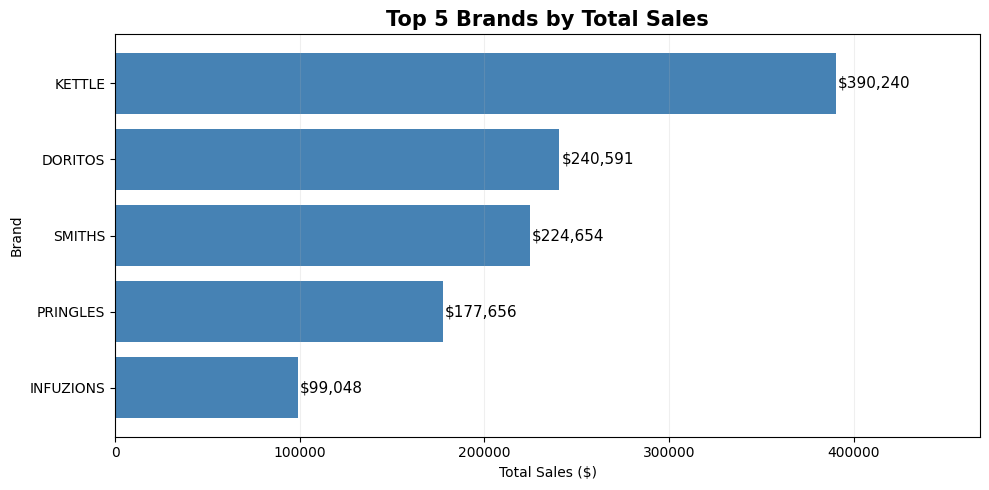

In [31]:
# Draw the five brands with the most sales.
import matplotlib.pyplot as plt

# Top 5 brands by total sales
top_brands = brand_performance.head(5).sort_values("total_sales")

plt.figure(figsize=(10, 5))

bars = plt.barh(
    top_brands["BRAND"],
    top_brands["total_sales"],
    color="steelblue"
)

# Add sales values to bars
for bar in bars:
    plt.text(
        bar.get_width() + 1000,
        bar.get_y() + bar.get_height() / 2,
        f'${bar.get_width():,.0f}',
        va="center",
        fontsize=11
    )

plt.title("Top 5 Brands by Total Sales", fontsize=15, fontweight="bold")
plt.xlabel("Total Sales ($)")
plt.ylabel("Brand")

plt.xlim(0, top_brands["total_sales"].max() * 1.2)
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()

# Save high-resolution image for presentation
plt.savefig("top_5_brands.png", dpi=300, bbox_inches="tight")

plt.show()

In [32]:
# Show the brands with the least sales.
# Least popular brands
brand_performance.tail(5)

,BRAND,units_sold,total_sales
16,CCS,8609,18078.9
17,CHEETOS,5530,16884.5
18,SUNBITES,5692,9676.4
19,FRENCH,2643,7929.0
20,BURGER,2970,6831.0


In [33]:
# Count shopping visits and sales for each customer.
# Customer purchasing behavior
query = """
SELECT
    LYLTY_CARD_NBR,
    COUNT(DISTINCT TXN_ID) AS transactions,
    SUM(TOT_SALES) AS total_sales
FROM sales
GROUP BY LYLTY_CARD_NBR;
"""

customer_summary = pd.read_sql_query(
    query,
    conn
)

In [34]:
# Label customers who bought once or more than once.
# Customer segments
customer_summary["customer_type"] = np.where(
    customer_summary["transactions"] >= 2,
    "Repeat",
    "One-Time"
)

In [35]:
# Show the share of customers who bought once or returned.
repeat_proportion = (
    customer_summary["customer_type"]
    .value_counts(normalize=True)
    * 100
)

repeat_proportion.round(2)

,proportion
customer_type,
Repeat,73.7
One-Time,26.3


In [36]:
# Compare spending by customers who bought once and those who returned.
customer_summary.groupby(
    "customer_type"
).agg(
    customers=("LYLTY_CARD_NBR", "count"),
    avg_transactions=("transactions", "mean"),
    avg_sales=("total_sales", "mean"),
    total_sales=("total_sales", "sum")
).round(2)

,customers,avg_transactions,avg_sales,total_sales
customer_type,,,,
One-Time,19105,1.00,6.42,122641.05
Repeat,53531,4.56,33.82,1810467.95


In [37]:
# Compare customer groups by sales and customer counts.
# Customer Lifestage and Premium
query = """
SELECT
    LIFESTAGE,
    PREMIUM_CUSTOMER,
    COUNT(DISTINCT LYLTY_CARD_NBR) AS customers,
    SUM(TOT_SALES) AS total_sales
FROM sales
GROUP BY
    LIFESTAGE,
    PREMIUM_CUSTOMER
ORDER BY total_sales DESC;
"""

segments = pd.read_sql_query(
    query,
    conn
)

In [38]:
# Find sales per customer for each customer group.
# display sales per customer for each type of premium customer
segments["sales_per_customer"] = (
    segments["total_sales"]
    / segments["customers"]
)

segments.round(2)

,LIFESTAGE,PREMIUM_CUSTOMER,customers,total_sales,sales_per_customer
0,OLDER FAMILIES,Budget,4675,168363.25,36.01
1,YOUNG SINGLES/COUPLES,Mainstream,8088,157621.60,19.49
2,RETIREES,Mainstream,6479,155677.05,24.03
3,YOUNG FAMILIES,Budget,4017,139345.85,34.69
4,OLDER SINGLES/COUPLES,Budget,4929,136769.80,27.75
5,OLDER SINGLES/COUPLES,Mainstream,4930,133393.80,27.06
6,OLDER SINGLES/COUPLES,Premium,4750,132257.15,27.84
7,RETIREES,Budget,4454,113147.80,25.40
8,OLDER FAMILIES,Mainstream,2831,103445.55,36.54
9,RETIREES,Premium,3872,97646.05,25.22


### Group customers by shopping history
We look at how recently customers bought, how often they bought and their total spending. These measures are often called **RFM**. The groups below describe past shopping behaviour; they do not prove what caused the trial results.

In [39]:
# Measure how recently and how often each customer bought, and how much they spent.
snapshot_date = (
    df["DATE"].max()
    + pd.Timedelta(days=1)
)

rfm = df.groupby(
    "LYLTY_CARD_NBR"
).agg(
    last_purchase=("DATE", "max"),
    Frequency=("TXN_ID", "nunique"),
    Monetary=("TOT_SALES", "sum")
).reset_index()

rfm["Recency"] = (
    snapshot_date
    - rfm["last_purchase"]
).dt.days

In [40]:
# Find middle values to divide customers into broad groups.
recency_median = rfm["Recency"].median()
frequency_median = rfm["Frequency"].median()
monetary_median = rfm["Monetary"].median()

In [41]:
# Create simple customer groups using shopping history.
# create RFM function
def create_segment(row):

    if (
        row["Recency"] <= recency_median
        and row["Frequency"] >= frequency_median
        and row["Monetary"] >= monetary_median
    ):
        return "High Value"

    elif (
        row["Frequency"] >= frequency_median
        and row["Recency"] > recency_median
    ):
        return "At Risk"

    elif row["Recency"] <= recency_median:
        return "Recent"

    else:
        return "Low Engagement"

In [42]:
# Assign a group to each customer.
rfm["Segment"] = rfm.apply(
    create_segment,
    axis=1
)

In [60]:
# Show how much each customer group contributed to sales.
# Display RFM segments with sales contribution
rfm_summary = rfm.groupby("Segment").agg(
    customers=("LYLTY_CARD_NBR", "count"),
    avg_recency=("Recency", "mean"),
    avg_frequency=("Frequency", "mean"),
    avg_spend=("Monetary", "mean"),
    total_sales=("Monetary", "sum")
)

# Calculate percentage of total sales
rfm_summary["sales_contribution_pct"] = (
    rfm_summary["total_sales"]
    / rfm_summary["total_sales"].sum()
    * 100
)

# Sort by highest sales contribution
rfm_summary = rfm_summary.sort_values(
    "sales_contribution_pct",
    ascending=False
)

# Display results
display(rfm_summary.round(1))

,customers,avg_recency,avg_frequency,avg_spend,total_sales,sales_contribution_pct
Segment,,,,,,
High Value,25214,31.3,6.1,45.8,1153750.6,59.7
At Risk,12620,133.1,4.5,34.1,430585.9,22.3
Low Engagement,23455,203.9,1.4,9.1,214230.2,11.1
Recent,11347,37.3,1.9,11.9,134542.2,7.0


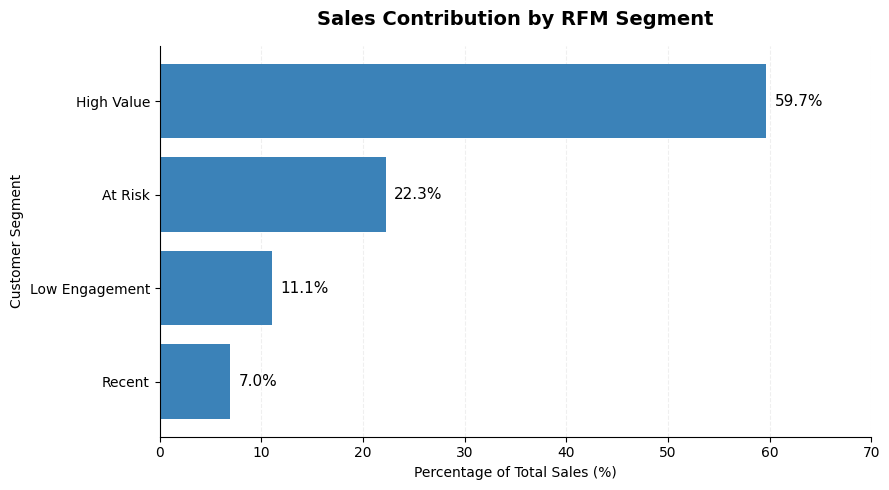

In [62]:
# Visualize sales contribution by RFM segment

import matplotlib.pyplot as plt

# Sort segments by sales contribution
rfm_plot = rfm_summary.sort_values(
    "sales_contribution_pct",
    ascending=True
)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    rfm_plot.index,
    rfm_plot["sales_contribution_pct"],
    color="#3B82B8"
)

# Add percentage labels
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center",
        fontsize=11
    )

# Format chart
ax.set_title(
    "Sales Contribution by RFM Segment",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Percentage of Total Sales (%)")
ax.set_ylabel("Customer Segment")
ax.set_xlim(0, 70)

# Clean up chart
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

# Save chart for PowerPoint
plt.savefig(
    "rfm_sales_contribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Step 8. Did the store trial improve sales?
From **February to April 2019**, stores **77, 86 and 88** took part in a trial. We want to see whether their sales improved during those three months.

We compare each trial store with a similar store that did not take part. We call that comparison store a **control store**. For example, store 77 is compared with store 233.

We first check how the stores performed **before the trial, from July 2018 to January 2019**. This helps us choose a fair comparison. We then look at sales, customer numbers and how often customers bought products during the trial.

The first chart shows **the actual sales recorded at both stores**. Later, we adjust the control store's sales to allow for any usual difference in store size. That adjusted figure helps us estimate whether the trial store did better than expected.

Finally, we check whether the sales differences are large enough to stand out from normal ups and downs. We use a paired t-test covering the full trial to compare average daily sales with the adjusted control. Its p-values help us decide whether to reject the null hypothesis of no average daily sales difference.

### 1. Summarize each store's monthly performance
For each store and month, the code adds up sales and counts customers, shopping visits and units sold. It also works out how often customers bought products, how many units they bought per visit and the average sales value per unit.

In [44]:
# Create a monthly summary for each store.
store_month = df.groupby(['STORE_NBR', 'YEAR_MONTH']).agg(
    total_sales=('TOT_SALES', 'sum'), customers=('LYLTY_CARD_NBR', 'nunique'),
    transactions=('TXN_ID', 'nunique'), units=('PROD_QTY', 'sum')
).reset_index()
store_month['transactions_per_customer'] = store_month['transactions'] / store_month['customers']
store_month['units_per_transaction'] = store_month['units'] / store_month['transactions']
store_month['price_per_unit'] = store_month['total_sales'] / store_month['units']

### 2. Split the data into three periods
- **Before the trial:** July 2018–January 2019. Use this period to choose comparison stores and understand their usual sales.
- **During the trial:** February–April 2019. Use all three months to assess the trial.
- **After the trial:** May–June 2019. See what happened once the trial ended.

Only stores with records in all 12 months are considered as comparison stores.

In [45]:
# Separate the before, during and after-trial periods.
trial_stores = [77, 86, 88]
PRE_START, TRIAL_START, TRIAL_END, POST_END = '2018-07', '2019-02', '2019-05', '2019-07'
full_stores = store_month.groupby('STORE_NBR')['YEAR_MONTH'].nunique()
full_stores = full_stores[full_stores == 12].index
pre_trial = store_month[
    store_month['YEAR_MONTH'].between(PRE_START, '2019-01')
    & store_month['STORE_NBR'].isin(full_stores)
].copy()
trial_period = store_month[store_month['YEAR_MONTH'].between('2019-02', '2019-04')].copy()
post_trial = store_month[store_month['YEAR_MONTH'].between('2019-05', '2019-06')].copy()

### 3. Understand how stores performed before the trial
The next table shows each store's average monthly sales, customer numbers and shopping visits per customer before February. It gives us a starting point for choosing similar stores.

In [46]:
# Find each store's average monthly performance before the trial.
pre_trial_summary = (
    pre_trial.groupby("STORE_NBR")
    .agg(
        avg_sales=("total_sales", "mean"),
        avg_customers=("customers", "mean"),
        avg_transactions_per_customer=(
            "transactions_per_customer",
            "mean"
        )
    )
    .reset_index()
)

In [47]:
# Score how similar each eligible comparison store was before the trial.
def find_controls(trial_store):
    scores = pd.DataFrame(index=full_stores)
    for metric in ['total_sales', 'customers']:
        values = pre_trial.pivot(index='YEAR_MONTH', columns='STORE_NBR', values=metric)
        distance = values.sub(values[trial_store], axis=0).abs()
        span = distance.max(axis=1) - distance.min(axis=1)
        magnitude = 1 - distance.sub(distance.min(axis=1), axis=0).div(span, axis=0)
        scores[f'{metric}_correlation'] = values.corrwith(values[trial_store])
        scores[f'{metric}_magnitude'] = magnitude.mean()
    # Four components have equal weight, matching the template.
    scores['Similarity'] = scores.mean(axis=1, skipna=False)
    scores.index.name = 'Control Store'
    scores = scores.reset_index()
    scores['Trial Store'] = trial_store
    return scores[~scores['Control Store'].isin(trial_stores)].dropna().sort_values(
        ['Similarity', 'Control Store'], ascending=[False, True]
    ).reset_index(drop=True)

In [48]:
# Show the five closest matches for store 77.
display(find_controls(77).head(5).round(6))

,Control Store,total_sales_correlation,total_sales_magnitude,customers_correlation,customers_magnitude,Similarity,Trial Store
0,233,0.903774,0.985265,0.990358,0.992773,0.968043,77
1,41,0.783232,0.965140,0.844219,0.974639,0.891808,77
2,17,0.842668,0.880688,0.747308,0.962495,0.858290,77
3,254,0.577108,0.922771,0.916208,0.937131,0.838305,77
4,115,0.689159,0.932832,0.718882,0.965916,0.826697,77


In [49]:
# Show the five closest matches for store 86.
display(find_controls(86).head(5).round(6))

,Control Store,total_sales_correlation,total_sales_magnitude,customers_correlation,customers_magnitude,Similarity,Trial Store
0,155,0.877882,0.962964,0.942876,0.985037,0.942190,86
1,109,0.788300,0.961985,0.770778,0.965940,0.871751,86
2,114,0.734415,0.919281,0.855339,0.935508,0.861136,86
3,138,0.759864,0.923719,0.749701,0.928031,0.840329,86
4,225,0.617533,0.956330,0.733791,0.967367,0.818755,86


In [50]:
# Show the five closest matches for store 88.
display(find_controls(88).head(5).round(6))

,Control Store,total_sales_correlation,total_sales_magnitude,customers_correlation,customers_magnitude,Similarity,Trial Store
0,237,0.308479,0.956076,0.947326,0.987586,0.799867,88
1,178,0.731857,0.695854,0.939466,0.821154,0.797083,88
2,69,0.450029,0.707811,0.815792,0.868984,0.710654,88
3,113,0.495763,0.682806,0.862632,0.784059,0.706315,88
4,201,0.492735,0.873034,0.511302,0.920577,0.699412,88


### 4. Check whether the stores followed similar sales patterns
A good comparison store should have similar sales and customer numbers before the trial. Its sales should also rise and fall in a similar way. The matching score combines those checks; a higher score means a closer match.

The extra function below checks how closely the sales patterns moved together. A result close to 1 means the patterns were very similar. It is available for checking individual pairs; it is not an extra step in selecting the controls.

In [51]:
# Provide an extra check of how closely two stores' sales patterns moved together.
def check_correlation(
    trial_store,
    control_store
):

    trial = pre_trial[
        pre_trial["STORE_NBR"]
        == trial_store
    ]

    control = pre_trial[
        pre_trial["STORE_NBR"]
        == control_store
    ]

    comparison = trial[
        ["YEAR_MONTH", "total_sales"]
    ].merge(
        control[
            ["YEAR_MONTH", "total_sales"]
        ],
        on="YEAR_MONTH",
        suffixes=("_trial", "_control")
    )

    return comparison[
        "total_sales_trial"
    ].corr(
        comparison[
            "total_sales_control"
        ]
    )

### 5. Choose the comparison stores
For each trial store, choose the eligible store with the highest matching score. The code works out the scores using sales and customer numbers before the trial.

The selected pairs are **77 and 233**, **86 and 155**, and **88 and 237**. Shopping visits per customer are reviewed later to help explain the results.

In [52]:
# Show the best comparison store and its matching score for each trial store.
control_rankings = pd.concat([find_controls(s) for s in trial_stores], ignore_index=True)
matching_results = pd.DataFrame([find_controls(s).iloc[0] for s in trial_stores])
display(matching_results[['Trial Store', 'Control Store', 'Similarity']].round(2))

,Trial Store,Control Store,Similarity
0,77.0,233.0,0.97
0,86.0,155.0,0.94
0,88.0,237.0,0.80


In [53]:
# Put each store pair together and allow for their usual differences before the trial.
controls = dict(zip(matching_results['Trial Store'].astype(int),
                    matching_results['Control Store'].astype(int)))
comparisons = {}
for trial_store, control_store in controls.items():
    comp = store_month[store_month['STORE_NBR'] == trial_store].merge(
        store_month[store_month['STORE_NBR'] == control_store],
        on='YEAR_MONTH', suffixes=('_trial', '_control'), validate='one_to_one'
    ).sort_values('YEAR_MONTH').copy()
    baseline = comp['YEAR_MONTH'].between(PRE_START, '2019-01')
    for metric in ['total_sales', 'customers', 'transactions_per_customer',
                   'units_per_transaction', 'price_per_unit']:
        scale = comp.loc[baseline, f'{metric}_trial'].sum() / comp.loc[baseline, f'{metric}_control'].sum()
        comp[f'{metric}_scale'] = scale
        comp[f'{metric}_expected'] = comp[f'{metric}_control'] * scale
        comp[f'{metric}_lift'] = comp[f'{metric}_trial'] / comp[f'{metric}_expected'] - 1
    comparisons[trial_store] = comp

### 6. Compare actual sales at each pair of stores
The chart below shows the sales actually recorded at each trial store and its comparison store. **No adjustment is made to either line.** The shaded area covers the trial, from February through April 2019.

This chart helps us see when sales rose or fell. Because stores may normally sell different amounts, a trial store being above its comparison store does not by itself tell us how much improvement came from the trial.

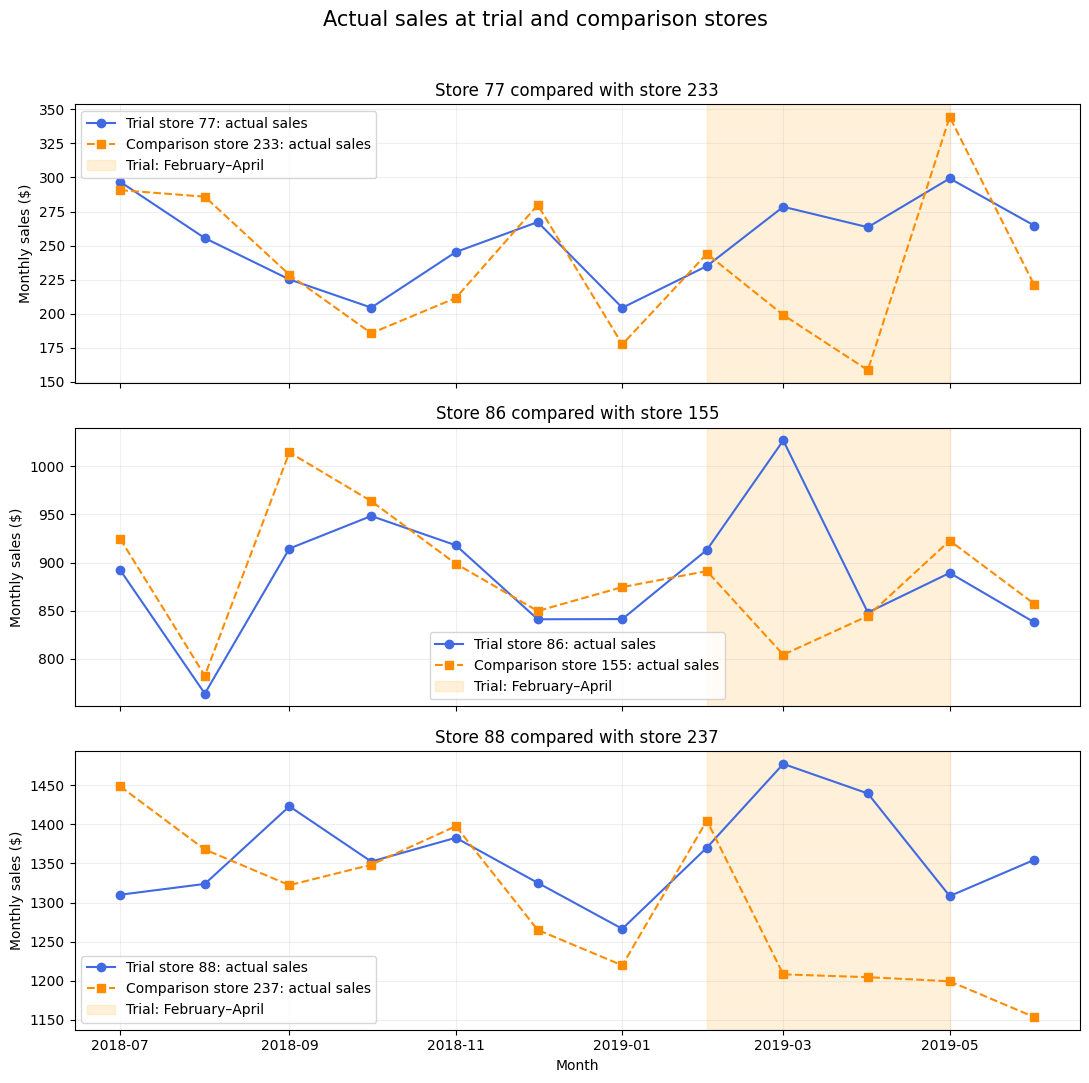

In [54]:
# Show actual monthly sales at the trial store and its comparison store.
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
for ax, (trial_store, control_store) in zip(axes, controls.items()):
    comp = comparisons[trial_store]
    dates = pd.to_datetime(comp['YEAR_MONTH'])
    ax.plot(dates, comp['total_sales_trial'], color='royalblue', marker='o',
            label=f'Trial store {trial_store}: actual sales')
    ax.plot(dates, comp['total_sales_control'], color='darkorange', marker='s', linestyle='--',
            label=f'Comparison store {control_store}: actual sales')
    ax.axvspan(pd.Timestamp('2019-02-01'), pd.Timestamp('2019-05-01'),
               alpha=0.15, color='orange', label='Trial: February–April')
    ax.set_title(f'Store {trial_store} compared with store {control_store}')
    ax.set_ylabel('Monthly sales ($)')
    ax.legend()
    ax.grid(alpha=0.2)
axes[-1].set_xlabel('Month')
fig.suptitle('Actual sales at trial and comparison stores', fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('trial_vs_control_actual_sales.png', dpi=160, bbox_inches='tight')
plt.show()

Each chart shows one store pair. The blue line is the trial store's actual sales; the orange dashed line is the comparison store's actual sales. The shaded area marks the three trial months.

The next section allows for the stores' usual sales differences before calculating sales improvement.

### Measure sales lift
To measure the impact of the **February–April 2019 trial**, actual sales are compared with expected sales for each treatment store.

Expected sales are estimated using matched control stores, adjusted for differences in sales performance before the trial.

**Sales Lift ($)** = Actual Sales − Expected Sales

**Sales Lift (%)** = (Actual Sales − Expected Sales) / Expected Sales × 100

A positive sales lift indicates that a store performed above expectations.

The next table shows the estimated sales lift during **February–April** and after the trial during **May–June**. These percentages use adjusted expected sales, rather than the control store's unadjusted sales.

In [55]:
# Calculate sales lift during trial and after trial
rows = []
for trial_store, control_store in controls.items():
    comp = comparisons[trial_store]
    for period, first, last in [('Trial', '2019-02', '2019-04'), ('Post-Trial', '2019-05', '2019-06')]:
        values = comp[comp['YEAR_MONTH'].between(first, last)]
        actual = values['total_sales_trial'].sum()
        expected = values['total_sales_expected'].sum()
        rows.append({'Trial Store': trial_store, 'Control Store': control_store, 'Period': period,
                     'Actual Sales': actual, 'Control Sales': values['total_sales_control'].sum(),
                     'Expected Sales': expected, 'Sales Lift ($)': actual - expected,
                     'Sales Lift (%)': (actual / expected - 1) * 100})
period_results_df = pd.DataFrame(rows)
sales_results_df = period_results_df[period_results_df['Period'] == 'Trial'].copy()

# Show trial and post-trial sales lift side by side.
lift_comparison = period_results_df.pivot(
    index=['Trial Store', 'Control Store'], columns='Period', values='Sales Lift (%)'
).reset_index()
lift_comparison.columns.name = None
lift_comparison = lift_comparison.rename(columns={
    'Trial': 'Trial Sales Lift (%)', 'Post-Trial': 'Post-Trial Sales Lift (%)'
})
lift_comparison = lift_comparison[['Trial Store', 'Control Store',
    'Trial Sales Lift (%)', 'Post-Trial Sales Lift (%)']]
display(lift_comparison.round(2))

,Trial Store,Control Store,Trial Sales Lift (%),Post-Trial Sales Lift (%)
0,77,233,26.15,-2.55
1,86,155,13.15,0.03
2,88,237,12.12,13.00


In [56]:
# Calculate one combined sales lift for all three trial stores, February–April.
total_actual = sales_results_df['Actual Sales'].sum()
total_expected = sales_results_df['Expected Sales'].sum()
combined_lift = (total_actual - total_expected) / total_expected * 100
print(f'Combined Trial Sales Lift: {combined_lift:+.2f}%')

Combined Trial Sales Lift: +13.74%


### Run a t-test and review the p-value
We used a **paired t-test** to compare each trial store's daily sales with its matched control store during **February–April 2019**. We paired sales from the same dates and adjusted the control's sales to allow for the stores' usual differences before the trial.

The test asks: **Was the average daily sales difference large enough to stand out from normal variation?** It checks for a difference in either direction—higher or lower sales.

We tested two hypotheses:

- **Null hypothesis (H₀):** The trial store and its adjusted control have the same average daily sales during the trial.
- **Alternative hypothesis (H₁):** Their average daily sales are different.

The test produces a **t-statistic**, which is the score used to calculate the **p-value**. The p-value tells us how unusual a result at least this large would be if H₀ were true and the test's assumptions held. It is not the probability that H₀ is true.

We used **0.05** as our decision cutoff:

- **p-value below 0.05:** Reject H₀; the test supports H₁.
- **p-value of 0.05 or higher:** Fail to reject H₀; there is not enough evidence to support H₁.

In [57]:
# Run test for each trial/control pair across February–April.
test_rows = []
for trial_store, control_store in controls.items():
    daily = df[df['STORE_NBR'].isin([trial_store, control_store])].groupby(
        ['DATE', 'STORE_NBR'])['TOT_SALES'].sum().unstack()
    daily = daily.reindex(pd.date_range('2018-07-01', '2019-06-30')).fillna(0)
    pre = daily.loc['2018-07-01':'2019-01-31']
    scale = pre[trial_store].sum() / pre[control_store].sum()
    trial = daily.loc['2019-02-01':'2019-04-30']
    actual = trial[trial_store]
    expected = trial[control_store] * scale
    t_stat, p_value = stats.ttest_rel(actual, expected)
    test_rows.append({
        'Trial Store': trial_store, 'Control Store': control_store,
        'Trial Sales': actual.sum(), 'Control Sales': trial[control_store].sum(),
        'Expected Sales': expected.sum(),
        'Sales Lift (%)': (actual.sum() - expected.sum()) / expected.sum() * 100,
        'T-Statistic': t_stat, 'P-Value': p_value,
        'Decision': 'Reject H₀' if p_value < 0.05 else 'Fail to Reject H₀'
    })
# Show table for t-statistic, p-value and decision to reject or fail to reject null hypothesis
ttest_results_df = pd.DataFrame(test_rows)
ttest_results = ttest_results_df[
    ['Trial Store', 'Control Store', 'T-Statistic', 'P-Value', 'Decision']
].copy()
display(ttest_results.round(6))
hypothesis_results_df = ttest_results_df.copy()


,Trial Store,Control Store,T-Statistic,P-Value,Decision
0,77,233,1.771974,0.079860,Fail to Reject H₀
1,86,155,1.607190,0.111595,Fail to Reject H₀
2,88,237,1.595150,0.114264,Fail to Reject H₀


### Which hypothesis did the results support?

All three p-values are above 0.05. We therefore **failed to reject the null hypothesis for all three stores**. The test did not provide enough evidence to conclude that average daily sales were different during the trial.


### Actual and expected sales comparison
The chart compares actual and expected sales for treatment stores 77, 86, and 88.

Expected sales were estimated using matched control stores and adjusted for differences in historical sales performance.

During **February–April 2019**, the actual sales of each treatment store were compared with their expected sales to evaluate whether the trial was associated with improved performance.

Stores where actual sales exceeded expected sales demonstrated positive estimated sales lift, while stores performing below expectations demonstrated negative estimated sales lift.

The chart below uses the adjusted expected amount and shows the same p-values as the test table. Later, the actual-sales chart shows the control stores' recorded sales without this adjustment.

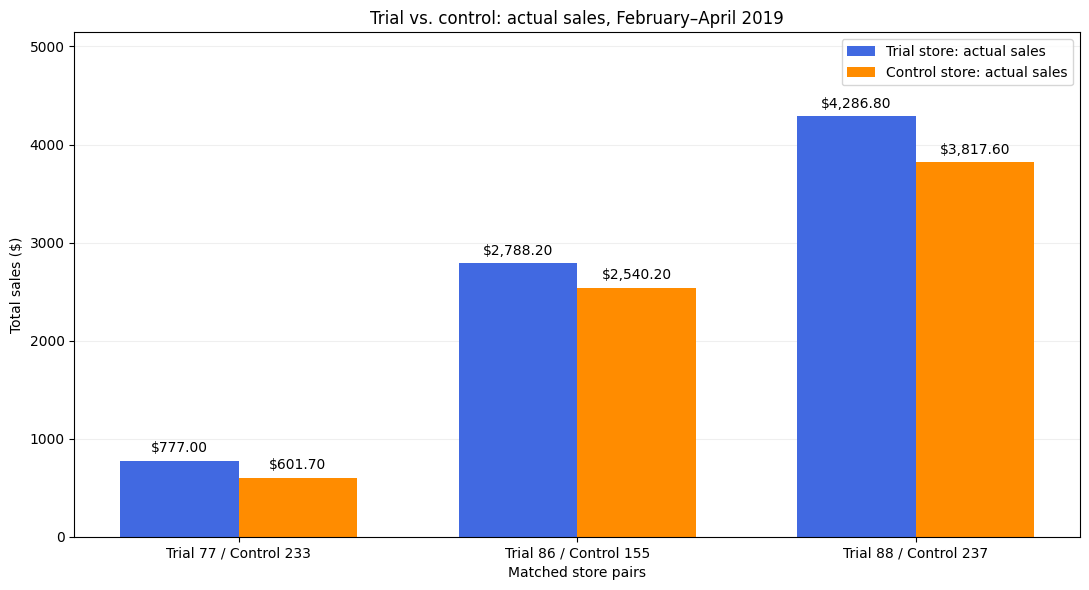

In [58]:
# grouped bar chart (3 groups - 77/233, 86/155, and 88/237)
x = np.arange(len(ttest_results_df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

trial_bars = ax.bar(
    x - width / 2,
    ttest_results_df['Trial Sales'],
    width,
    label='Trial store: actual sales',
    color='royalblue'
)

control_bars = ax.bar(
    x + width / 2,
    ttest_results_df['Control Sales'],
    width,
    label='Control store: actual sales',
    color='darkorange'
)

# Show sales amounts above the bars
for bars in [trial_bars, control_bars]:
    ax.bar_label(
        bars,
        labels=[f'${bar.get_height():,.2f}' for bar in bars],
        padding=4
    )

# Label each store pair
ax.set_xticks(x)
ax.set_xticklabels([
    f"Trial {int(row['Trial Store'])} / Control {int(row['Control Store'])}"
    for _, row in ttest_results_df.iterrows()
])

ax.set_title('Trial vs. control: actual sales, February–April 2019')
ax.set_xlabel('Matched store pairs')
ax.set_ylabel('Total sales ($)')
ax.legend()

ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)

highest_sales = max(
    ttest_results_df['Trial Sales'].max(),
    ttest_results_df['Control Sales'].max()
)
ax.set_ylim(0, highest_sales * 1.2)

plt.tight_layout()
plt.savefig(
    'ab_testing_sales_comparison.png',
    dpi=160,
    bbox_inches='tight'
)
plt.show()

### Additional Analysis: What Drove Sales Changes?
Were sales changes driven by more purchasing customers or more purchases per customer?

We compared two metrics against matched control stores:

- **Purchasing Customers:** Number of unique customers.
- **Purchases per Customer:** Average transactions per customer.



In [59]:
# Summarize customer behaviour across February–April: one row per store pair.
rows = []
for trial_store, control_store in controls.items():
    trial = comparisons[trial_store]
    trial = trial[trial['YEAR_MONTH'].between('2019-02', '2019-04')]
    customer_change = (trial['customers_trial'].mean()
                       / trial['customers_expected'].mean() - 1) * 100
    purchase_change = (trial['transactions_per_customer_trial'].mean()
                       / trial['transactions_per_customer_expected'].mean() - 1) * 100
    rows.append({
        'Store pair': f'Trial {trial_store} vs. control {control_store}',
        'Customer change (%)': customer_change,
        'Purchases per customer change (%)': purchase_change
    })
customer_summary = pd.DataFrame(rows).set_index('Store pair')
display(customer_summary.round(2))

,Customer change (%),Purchases per customer change (%)
Store pair,,
Trial 77 vs. control 233,23.07,-2.03
Trial 86 vs. control 155,13.54,0.66
Trial 88 vs. control 237,6.35,6.41


### Customer Behavior Insights
We looked at whether sales changes were linked to more customers, more purchases per customer, or both.
- **Store 77 vs. control 233**: The stronger sales were mainly associated with more customers. Customers did not consistently buy more often, so increased purchase frequency was not the main positive pattern.
- **Store 86 vs. control 155**: Customer numbers grew while purchases per customer stayed fairly steady. This suggests that serving more customers was more closely linked to the sales improvement than customers shopping more often.
- **Store 88 vs. control 237**: Both customer numbers and purchases per customer improved later in the trial. More customers and more frequent purchases together helped explain the stronger sales pattern.

These patterns suggest that customer growth was the main positive factor at stores 77 and 86, while both customer growth and purchase frequency contributed at store 88. They do not establish what caused the changes; prices, discounts and the products sold also affect sales.

### **Business Insights**
The trial ran from **February through April 2019** at stores **77, 86 and 88**. We compared them with similar stores **233, 155 and 237**.

All three trial stores sold more than we estimated they would based on how the comparison stores had performed before the trial. Together, their sales were about $948 higher than that estimate, an improvement of 13.74%. Store 77 showed the largest percentage increase.

Although sales were higher, the statistical result did not give us enough evidence to confirm that the difference was more than normal day-to-day ups and downs. We therefore cannot confidently say that the trial caused the extra sales. This does not mean the trial had no effect—it means we need more evidence.

Stores 77 and 86 mainly benefited from having more customers. At store 88, more customers and more frequent purchases both helped explain the stronger sales pattern.

### **Business Recommendation by Department**
**Category/Marketing**: Test loyalty offers for high-value shoppers and win-back offers for at-risk customers

**Supply Chain**: Review stock levels and reorder plans for popular brands like Kettle before expanding the trial

**Store Operations**: Compare store traffic, displays and trial execution to see what might explain the differences


### **Final Recommendation**

Do not roll out company-wide yet.